CNN PERSONALIZADA

In [2]:
import pandas as pd
from pathlib import Path

# ============================================================
# DIRECTORIOS DEL PROYECTO
# ============================================================

PROJECT_ROOT = Path.cwd()

DATA_DIR = PROJECT_ROOT / "data"
IDRID_DIR = DATA_DIR / "IDRiD2"

# Archivos CSV
TRAIN_CSV = DATA_DIR / "train_split.csv"
VAL_CSV = DATA_DIR / "val_split.csv"

# Directorios de imágenes
TRAIN_IMAGES_DIR = IDRID_DIR / "IDRiD" / "train" / "images"
TEST_IMAGES_DIR = IDRID_DIR / "IDRiD" / "test" / "images"

# ============================================================
# VERIFICAR ARCHIVOS CSV
# ============================================================

print("Directorio del proyecto:", PROJECT_ROOT)

for archivo in [TRAIN_CSV, VAL_CSV]:
    print(archivo, "Existe:", archivo.exists())

if not TRAIN_CSV.exists() or not VAL_CSV.exists():
    raise FileNotFoundError(
        "No se encontraron los CSV. "
        "Verifica que PROJECT_ROOT corresponda a tu proyecto."
    )

# ============================================================
# CARGAR DATAFRAMES
# ============================================================

train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)

# ============================================================
# COMPROBACIÓN
# ============================================================

print("\n===== DATASETS CARGADOS =====")

print("TRAIN:", train_df.shape)
print("VAL:", val_df.shape)

print("\nColumnas TRAIN:")
print(train_df.columns.tolist())

print("\nColumnas VAL:")
print(val_df.columns.tolist())

print("\nPrimeras filas TRAIN:")
display(train_df.head())

print("\nPrimeras filas VAL:")
display(val_df.head())

Directorio del proyecto: c:\Users\lauri\Documents\PROYECTO_FINAL
c:\Users\lauri\Documents\PROYECTO_FINAL\data\train_split.csv Existe: True
c:\Users\lauri\Documents\PROYECTO_FINAL\data\val_split.csv Existe: True

===== DATASETS CARGADOS =====
TRAIN: (2640, 9)
VAL: (83, 9)

Columnas TRAIN:
['Image name', 'Retinopathy grade', 'Risk of macular edema', 'class', 'Captions', 'binary_label', 'patient_id', 'is_original', 'model_split']

Columnas VAL:
['Image name', 'Retinopathy grade', 'Risk of macular edema', 'class', 'Captions', 'binary_label', 'patient_id', 'is_original', 'model_split']

Primeras filas TRAIN:


,Image name,Retinopathy grade,Risk of macular edema,class,Captions,binary_label,patient_id,is_original,model_split
0,IDRiD_001,3,2,Clinically_Significant_Macular_Edema,Severe diabetic retinopathy with extensive ret...,1,IDRiD_001,True,train
1,IDRiD_002,3,2,Clinically_Significant_Macular_Edema,Severe nonproliferative diabetic retinopathy w...,1,IDRiD_002,True,train
2,IDRiD_004,3,2,Clinically_Significant_Macular_Edema,Severe diabetic retinopathy with extensive ret...,1,IDRiD_004,True,train
3,IDRiD_005,4,0,Severe_PDR,Fundoscopic examination reveals proliferative ...,1,IDRiD_005,True,train
4,IDRiD_006,4,1,Severe_PDR,Proliferative diabetic retinopathy with neovas...,1,IDRiD_006,True,train



Primeras filas VAL:


,Image name,Retinopathy grade,Risk of macular edema,class,Captions,binary_label,patient_id,is_original,model_split
0,IDRiD_003,2,2,Clinically_Significant_Macular_Edema,Advanced nonproliferative diabetic changes wit...,1,IDRiD_003,True,val
1,IDRiD_012,3,2,Clinically_Significant_Macular_Edema,Severe diabetic retinopathy with extensive ret...,1,IDRiD_012,True,val
2,IDRiD_028,4,2,Severe_PDR,Advanced proliferative diabetic retinopathy wi...,1,IDRiD_028,True,val
3,IDRiD_029,2,2,Clinically_Significant_Macular_Edema,Moderate nonproliferative diabetic retinopathy...,1,IDRiD_029,True,val
4,IDRiD_031,4,2,Severe_PDR,Proliferative diabetic retinopathy with neovas...,1,IDRiD_031,True,val


In [4]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from tensorflow import keras
from tensorflow.keras import layers, regularizers

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
)

# ============================================================
# CONFIGURACIÓN GENERAL
# ============================================================

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 16
EPOCHS = 50
LEARNING_RATE = 1e-3
THRESHOLD = 0.50

CLASS_NAMES = {
    0: "No referible",
    1: "Referible",
}

keras.utils.set_random_seed(SEED)

OUTPUT_DIR = Path("resultados_cnn_personalizada")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = OUTPUT_DIR / "mejor_cnn_personalizada.keras"

# ============================================================
# VERIFICAR COLUMNAS
# ============================================================

required_columns = [
    "patient_id",
    "image_path",
    "binary_label",
]

for name, df in [
    ("TRAIN", train_df),
    ("VAL", val_df),
]:
    missing = [
        col for col in required_columns
        if col not in df.columns
    ]

    if missing:
        raise ValueError(
            f"{name}: faltan columnas {missing}"
        )

# ============================================================
# SELECCIONAR IMÁGENES ORIGINALES
# ============================================================

SOLO_ORIGINALES = True

train_cnn = train_df.copy()
val_cnn = val_df.copy()

if SOLO_ORIGINALES:

    if "is_original" in train_cnn.columns:

        original_mask = (
            train_cnn["is_original"]
            .astype(str)
            .str.lower()
            .str.strip()
            .isin(["true", "1", "yes", "si"])
        )

    elif "Image name" in train_cnn.columns:

        image_names = train_cnn["Image name"].astype(str).map(
            lambda x: Path(x).stem.lower()
        )

        patient_names = (
            train_cnn["patient_id"]
            .astype(str)
            .str.strip()
            .str.lower()
        )

        original_mask = image_names.eq(patient_names)

    else:
        raise ValueError(
            "No existe una columna para identificar "
            "las imágenes originales. No se filtrará "
            "el entrenamiento sin verificarlo."
        )

    train_cnn = train_cnn.loc[original_mask].copy()

# ============================================================
# AUDITORÍA POR PACIENTE
# ============================================================

train_cnn = train_cnn.reset_index(drop=True)
val_cnn = val_cnn.reset_index(drop=True)

train_patients = set(
    train_cnn["patient_id"].astype(str).str.strip()
)

val_patients = set(
    val_cnn["patient_id"].astype(str).str.strip()
)

shared_patients = train_patients & val_patients

print("===== AUDITORÍA CNN =====")

print("\nTRAIN")
print("Imágenes:", len(train_cnn))
print("Pacientes:", len(train_patients))

print("\nVALIDACIÓN")
print("Imágenes:", len(val_cnn))
print("Pacientes:", len(val_patients))

print("\nPacientes compartidos:", len(shared_patients))

assert len(shared_patients) == 0, (
    "ERROR: existe fuga de información por paciente."
)

assert len(train_cnn) > 0, (
    "No se identificaron imágenes originales."
)

assert len(val_cnn) > 0

for nombre, df in [
    ("TRAIN", train_cnn),
    ("VAL", val_cnn),
]:
    assert df["binary_label"].notna().all()

    assert df["binary_label"].isin([0, 1]).all(), (
        f"{nombre}: existen etiquetas distintas de 0 y 1."
    )

    missing_paths = [
        p for p in df["image_path"].astype(str)
        if not Path(p).is_file()
    ]

    assert not missing_paths, (
        f"{nombre}: faltan {len(missing_paths)} archivos. "
        f"Ejemplo: {missing_paths[:3]}"
    )

print("\nDistribución TRAIN:")
print(train_cnn["binary_label"].value_counts().sort_index())

print("\nDistribución VAL:")
print(val_cnn["binary_label"].value_counts().sort_index())

print("\nAUDITORÍA COMPLETADA")

ValueError: TRAIN: faltan columnas ['image_path']

In [5]:
print("===== COLUMNAS TRAIN =====")
print(train_df.columns.tolist())

print("\n===== COLUMNAS VAL =====")
print(val_df.columns.tolist())

print("\n===== EJEMPLOS TRAIN =====")
display(train_df.head(5))

print("\n===== EJEMPLOS VAL =====")
display(val_df.head(5))

===== COLUMNAS TRAIN =====
['Image name', 'Retinopathy grade', 'Risk of macular edema', 'class', 'Captions', 'binary_label', 'patient_id', 'is_original', 'model_split']

===== COLUMNAS VAL =====
['Image name', 'Retinopathy grade', 'Risk of macular edema', 'class', 'Captions', 'binary_label', 'patient_id', 'is_original', 'model_split']

===== EJEMPLOS TRAIN =====


,Image name,Retinopathy grade,Risk of macular edema,class,Captions,binary_label,patient_id,is_original,model_split
0,IDRiD_001,3,2,Clinically_Significant_Macular_Edema,Severe diabetic retinopathy with extensive ret...,1,IDRiD_001,True,train
1,IDRiD_002,3,2,Clinically_Significant_Macular_Edema,Severe nonproliferative diabetic retinopathy w...,1,IDRiD_002,True,train
2,IDRiD_004,3,2,Clinically_Significant_Macular_Edema,Severe diabetic retinopathy with extensive ret...,1,IDRiD_004,True,train
3,IDRiD_005,4,0,Severe_PDR,Fundoscopic examination reveals proliferative ...,1,IDRiD_005,True,train
4,IDRiD_006,4,1,Severe_PDR,Proliferative diabetic retinopathy with neovas...,1,IDRiD_006,True,train



===== EJEMPLOS VAL =====


,Image name,Retinopathy grade,Risk of macular edema,class,Captions,binary_label,patient_id,is_original,model_split
0,IDRiD_003,2,2,Clinically_Significant_Macular_Edema,Advanced nonproliferative diabetic changes wit...,1,IDRiD_003,True,val
1,IDRiD_012,3,2,Clinically_Significant_Macular_Edema,Severe diabetic retinopathy with extensive ret...,1,IDRiD_012,True,val
2,IDRiD_028,4,2,Severe_PDR,Advanced proliferative diabetic retinopathy wi...,1,IDRiD_028,True,val
3,IDRiD_029,2,2,Clinically_Significant_Macular_Edema,Moderate nonproliferative diabetic retinopathy...,1,IDRiD_029,True,val
4,IDRiD_031,4,2,Severe_PDR,Proliferative diabetic retinopathy with neovas...,1,IDRiD_031,True,val


In [7]:
from pathlib import Path
import hashlib

print("===== DIAGNÓSTICO DE RUTAS AMBIGUAS =====")

ejemplos = [
    "IDRiD_001",
    "IDRiD_002",
    "IDRiD_004",
    "IDRiD_005",
    "IDRiD_006",
]

for nombre in ejemplos:

    print(f"\nIMAGEN: {nombre}")

    coincidencias = list(dict.fromkeys(
        image_index.get(nombre.lower(), [])
    ))

    print("Archivos encontrados:", len(coincidencias))

    for i, ruta in enumerate(coincidencias, start=1):

        ruta = Path(ruta)

        print(f"\n  Archivo {i}")
        print("  Ruta:", ruta)
        print("  Extensión:", ruta.suffix)
        print("  Tamaño:", ruta.stat().st_size, "bytes")

        with open(ruta, "rb") as f:
            huella = hashlib.sha256(f.read()).hexdigest()

        print("  SHA256:", huella[:16])

    if len(coincidencias) == 2:

        archivos = [Path(p) for p in coincidencias]

        hash_1 = hashlib.sha256(
            archivos[0].read_bytes()
        ).hexdigest()

        hash_2 = hashlib.sha256(
            archivos[1].read_bytes()
        ).hexdigest()

        print(
            "\n¿Son archivos idénticos?",
            "SÍ" if hash_1 == hash_2 else "NO"
        )

print("\n===== FIN DEL DIAGNÓSTICO =====")

===== DIAGNÓSTICO DE RUTAS AMBIGUAS =====

IMAGEN: IDRiD_001
Archivos encontrados: 2

  Archivo 1
  Ruta: c:\Users\lauri\Documents\PROYECTO_FINAL\data\IDRiD2\IDRiD\train\images\IDRiD_001.jpg
  Extensión: .jpg
  Tamaño: 409680 bytes
  SHA256: 8cbb3482b62a7b4c

  Archivo 2
  Ruta: c:\Users\lauri\Documents\PROYECTO_FINAL\data\IDRiD2\IDRiD\test\images\IDRiD_001.jpg
  Extensión: .jpg
  Tamaño: 234390 bytes
  SHA256: 59e7d08b451d8ce4

¿Son archivos idénticos? NO

IMAGEN: IDRiD_002
Archivos encontrados: 2

  Archivo 1
  Ruta: c:\Users\lauri\Documents\PROYECTO_FINAL\data\IDRiD2\IDRiD\train\images\IDRiD_002.jpg
  Extensión: .jpg
  Tamaño: 401441 bytes
  SHA256: 60083dd0e9945c5f

  Archivo 2
  Ruta: c:\Users\lauri\Documents\PROYECTO_FINAL\data\IDRiD2\IDRiD\test\images\IDRiD_002.jpg
  Extensión: .jpg
  Tamaño: 307468 bytes
  SHA256: e771c52174be5d9a

¿Son archivos idénticos? NO

IMAGEN: IDRiD_004
Archivos encontrados: 2

  Archivo 1
  Ruta: c:\Users\lauri\Documents\PROYECTO_FINAL\data\IDRiD2\IDRi

In [8]:
from pathlib import Path
from collections import defaultdict

# ============================================================
# 1. DIRECTORIO DE ORIGEN DEL SPLIT
# ============================================================

IMAGE_ROOT = Path(TRAIN_IMAGES_DIR)

assert IMAGE_ROOT.is_dir(), (
    f"No existe el directorio: {IMAGE_ROOT}"
)

# ============================================================
# 2. INDEXAR ARCHIVOS DE TRAIN/IMAGES
# ============================================================

extensions = {
    ".jpg", ".jpeg", ".png",
    ".tif", ".tiff", ".bmp"
}

index_name = defaultdict(list)
index_stem = defaultdict(list)

for path in IMAGE_ROOT.rglob("*"):

    if path.is_file() and path.suffix.lower() in extensions:

        index_name[path.name.lower()].append(path)
        index_stem[path.stem.lower()].append(path)

print("Archivos indexados:", sum(
    len(v) for v in index_name.values()
))

# ============================================================
# 3. IDENTIFICAR COLUMNA DE IMAGEN
# ============================================================

candidate_columns = [
    "Image name",
    "image_name",
    "image_filename",
    "filename",
    "file_name",
    "id_code",
    "image",
]

def find_image_column(df):

    for col in candidate_columns:
        if col in df.columns:
            return col

    raise ValueError(
        f"No se encontró columna de imagen: {df.columns.tolist()}"
    )

# ============================================================
# 4. RECONSTRUIR RUTAS
# ============================================================

def resolve_paths(df, dataset_name):

    df = df.copy()

    column = find_image_column(df)

    paths = []
    errors = []

    for value in df[column]:

        filename = Path(str(value).strip()).name

        if Path(filename).suffix:
            matches = index_name.get(
                filename.lower(), []
            )
        else:
            matches = index_stem.get(
                filename.lower(), []
            )

        matches = list(dict.fromkeys(matches))

        if len(matches) == 1:
            paths.append(str(matches[0].resolve()))

        else:
            paths.append(None)
            errors.append(
                (value, len(matches))
            )

    df["image_path"] = paths

    print(f"\n===== {dataset_name} =====")
    print("Registros:", len(df))
    print("Rutas encontradas:", df["image_path"].notna().sum())
    print("Errores:", len(errors))

    if errors:
        print("Ejemplos:", errors[:10])
        raise ValueError(
            f"{dataset_name}: existen rutas sin resolver."
        )

    return df

# ============================================================
# 5. APLICAR A TRAIN Y VAL
# ============================================================

train_resuelto = resolve_paths(
    train_df, "TRAIN"
)

val_resuelto = resolve_paths(
    val_df, "VALIDACIÓN"
)

# ============================================================
# 6. VERIFICAR FUGA DE INFORMACIÓN
# ============================================================

train_patients = set(
    train_resuelto["patient_id"].astype(str).str.strip()
)

val_patients = set(
    val_resuelto["patient_id"].astype(str).str.strip()
)

shared_patients = train_patients & val_patients

shared_paths = (
    set(train_resuelto["image_path"])
    & set(val_resuelto["image_path"])
)

print("\n===== AUDITORÍA FINAL =====")

print("TRAIN:", len(train_resuelto))
print("VAL:", len(val_resuelto))

print("Pacientes compartidos:", len(shared_patients))
print("Rutas compartidas:", len(shared_paths))

assert not shared_patients, (
    "ERROR: pacientes compartidos."
)

assert not shared_paths, (
    "ERROR: imágenes compartidas."
)

# Asignar solo después de superar las comprobaciones
train_df = train_resuelto
val_df = val_resuelto

print("\nRUTAS RESUELTAS CORRECTAMENTE")

Archivos indexados: 3304

===== TRAIN =====
Registros: 2640
Rutas encontradas: 2640
Errores: 0

===== VALIDACIÓN =====
Registros: 83
Rutas encontradas: 83
Errores: 0

===== AUDITORÍA FINAL =====
TRAIN: 2640
VAL: 83
Pacientes compartidos: 0
Rutas compartidas: 0

RUTAS RESUELTAS CORRECTAMENTE


In [9]:
from pathlib import Path

print("===== AUDITORÍA DE ARCHIVOS ADICIONALES =====")

IMAGE_ROOT = Path(TRAIN_IMAGES_DIR)

extensions = {
    ".jpg", ".jpeg", ".png",
    ".tif", ".tiff", ".bmp"
}

# Archivos disponibles en la carpeta original
all_images = {
    str(p.resolve())
    for p in IMAGE_ROOT.rglob("*")
    if p.is_file()
    and p.suffix.lower() in extensions
}

# Archivos utilizados por los CSV
train_images = set(
    train_df["image_path"].astype(str).map(
        lambda x: str(Path(x).resolve())
    )
)

val_images = set(
    val_df["image_path"].astype(str).map(
        lambda x: str(Path(x).resolve())
    )
)

# Imágenes que todavía no están en ningún CSV
unused_images = sorted(
    all_images - train_images - val_images
)

print("Total de imágenes:", len(all_images))
print("Imágenes TRAIN:", len(train_images))
print("Imágenes VAL:", len(val_images))
print("Imágenes adicionales:", len(unused_images))

print("\n===== EJEMPLOS TRAIN =====")
for p in sorted(train_images)[:10]:
    print(Path(p).name)

print("\n===== EJEMPLOS VAL =====")
for p in sorted(val_images)[:10]:
    print(Path(p).name)

print("\n===== ARCHIVOS ADICIONALES =====")
for p in unused_images[:30]:
    print(Path(p).name)

===== AUDITORÍA DE ARCHIVOS ADICIONALES =====
Total de imágenes: 3304
Imágenes TRAIN: 2640
Imágenes VAL: 83
Imágenes adicionales: 581

===== EJEMPLOS TRAIN =====
IDRiD_001.jpg
IDRiD_001_L14.jpg
IDRiD_001_L20.jpg
IDRiD_001_L6.jpg
IDRiD_001_R16.jpg
IDRiD_001_R22.jpg
IDRiD_001_R8.jpg
IDRiD_001_VFLIP.jpg
IDRiD_002.jpg
IDRiD_002_L14.jpg

===== EJEMPLOS VAL =====
IDRiD_003.jpg
IDRiD_012.jpg
IDRiD_028.jpg
IDRiD_029.jpg
IDRiD_031.jpg
IDRiD_040.jpg
IDRiD_045.jpg
IDRiD_046.jpg
IDRiD_052.jpg
IDRiD_053.jpg

===== ARCHIVOS ADICIONALES =====
IDRiD_003_L14.jpg
IDRiD_003_L20.jpg
IDRiD_003_L6.jpg
IDRiD_003_R16.jpg
IDRiD_003_R22.jpg
IDRiD_003_R8.jpg
IDRiD_003_VFLIP.jpg
IDRiD_012_L14.jpg
IDRiD_012_L20.jpg
IDRiD_012_L6.jpg
IDRiD_012_R16.jpg
IDRiD_012_R22.jpg
IDRiD_012_R8.jpg
IDRiD_012_VFLIP.jpg
IDRiD_028_L14.jpg
IDRiD_028_L20.jpg
IDRiD_028_L6.jpg
IDRiD_028_R16.jpg
IDRiD_028_R22.jpg
IDRiD_028_R8.jpg
IDRiD_028_VFLIP.jpg
IDRiD_029_L14.jpg
IDRiD_029_L20.jpg
IDRiD_029_L6.jpg
IDRiD_029_R16.jpg
IDRiD_029_R22.jpg

In [10]:
import re
import pandas as pd
from pathlib import Path
from collections import Counter

# ============================================================
# IDENTIFICAR IMÁGENES ORIGINALES
# ============================================================

def es_original(image_path):
    nombre = Path(str(image_path)).stem

    return bool(
        re.fullmatch(
            r"IDRiD_\d+",
            nombre,
            flags=re.IGNORECASE
        )
    )

# Clasificar registros existentes
train_audit = train_df.copy()
val_audit = val_df.copy()

train_audit["es_original"] = (
    train_audit["image_path"].apply(es_original)
)

val_audit["es_original"] = (
    val_audit["image_path"].apply(es_original)
)

# ============================================================
# SEPARAR ORIGINALES
# ============================================================

train_cnn = train_audit[
    train_audit["es_original"]
].copy().reset_index(drop=True)

val_cnn = val_audit[
    val_audit["es_original"]
].copy().reset_index(drop=True)

# ============================================================
# VERIFICAR LAS 581 IMÁGENES ADICIONALES
# ============================================================

def obtener_familia(path):
    nombre = Path(str(path)).stem

    match = re.match(
        r"^(IDRiD_\d+)(?:_|$)",
        nombre,
        flags=re.IGNORECASE
    )

    return match.group(1).lower() if match else None


familias_val = {
    obtener_familia(p)
    for p in val_cnn["image_path"]
}

conteo_adicional = Counter(
    obtener_familia(p)
    for p in unused_images
)

coinciden = (
    len(unused_images) == 581
    and len(familias_val) == 83
    and set(conteo_adicional) == familias_val
    and all(
        cantidad == 7
        for cantidad in conteo_adicional.values()
    )
)

print("===== AUDITORÍA DE IMÁGENES ORIGINALES =====")

print("\nTRAIN")
print("Originales:", len(train_cnn))
print("Pacientes:", train_cnn["patient_id"].nunique())

print("\nVALIDACIÓN")
print("Originales:", len(val_cnn))
print("Pacientes:", val_cnn["patient_id"].nunique())

print("\nArchivos adicionales:", len(unused_images))

print(
    "¿Las 581 imágenes son 7 variantes "
    "de cada paciente VAL?:",
    coinciden
)

# ============================================================
# COMPROBACIONES DE SEGURIDAD
# ============================================================

assert coinciden, (
    "Las imágenes adicionales no siguen "
    "exactamente el patrón esperado."
)

assert len(train_cnn) == 330
assert len(val_cnn) == 83

assert train_cnn["patient_id"].nunique() == 330
assert val_cnn["patient_id"].nunique() == 83

assert not (
    set(train_cnn["patient_id"].astype(str))
    & set(val_cnn["patient_id"].astype(str))
), "Existen pacientes compartidos."

assert set(train_cnn["binary_label"].unique()) == {0, 1}
assert set(val_cnn["binary_label"].unique()) == {0, 1}

print("\nAUDITORÍA SUPERADA")
print("Dataset preparado para CNN sin aumentación adicional.")

===== AUDITORÍA DE IMÁGENES ORIGINALES =====

TRAIN
Originales: 330
Pacientes: 330

VALIDACIÓN
Originales: 83
Pacientes: 83

Archivos adicionales: 581
¿Las 581 imágenes son 7 variantes de cada paciente VAL?: True

AUDITORÍA SUPERADA
Dataset preparado para CNN sin aumentación adicional.


In [11]:
import numpy as np
import pandas as pd
import tensorflow as tf

from pathlib import Path
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.utils.class_weight import compute_class_weight

# ============================================================
# CONFIGURACIÓN
# ============================================================

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 16
EPOCHS = 50
LEARNING_RATE = 1e-3

keras.utils.set_random_seed(SEED)

OUTPUT_DIR = Path("resultados_cnn_personalizada")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = OUTPUT_DIR / "mejor_cnn_personalizada.keras"

# ============================================================
# VERIFICACIÓN DE DATOS
# ============================================================

assert len(train_cnn) == 330
assert len(val_cnn) == 83

assert train_cnn["patient_id"].nunique() == 330
assert val_cnn["patient_id"].nunique() == 83

assert train_cnn["es_original"].all()
assert val_cnn["es_original"].all()

assert set(train_cnn["binary_label"].unique()) == {0, 1}
assert set(val_cnn["binary_label"].unique()) == {0, 1}

print("TRAIN:", len(train_cnn))
print("VAL:", len(val_cnn))

# ============================================================
# COMPROBACIÓN DE DECODIFICACIÓN
# ============================================================

for nombre, df in [
    ("TRAIN", train_cnn),
    ("VAL", val_cnn),
]:
    errores = []

    for path in df["image_path"].astype(str):
        try:
            imagen = tf.io.decode_image(
                tf.io.read_file(path),
                channels=3,
                expand_animations=False,
            )
            assert imagen.shape[-1] == 3
        except Exception as error:
            errores.append((path, str(error)))

    print(f"{nombre}: errores de lectura = {len(errores)}")

    if errores:
        print("Ejemplos:", errores[:5])
        raise ValueError(
            f"Corrige los archivos de {nombre} antes de entrenar."
        )

# ============================================================
# CARGAR IMÁGENES SIN DATA AUGMENTATION
# ============================================================

AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):

    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False,
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE],
    )

    image = tf.cast(image, tf.float32)

    return image, tf.cast(label, tf.float32)


def create_dataset(df, training=False):

    paths = df["image_path"].astype(str).to_numpy()

    labels = df["binary_label"].to_numpy(
        dtype=np.float32
    )

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            len(df),
            seed=SEED,
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE,
    )

    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)


train_ds = create_dataset(train_cnn, training=True)
val_ds = create_dataset(val_cnn, training=False)

# ============================================================
# CONSTRUIR CNN DESDE CERO
# ============================================================

inputs = keras.Input(
    shape=(IMG_SIZE, IMG_SIZE, 3)
)

x = layers.Rescaling(1.0 / 255)(inputs)

# BLOQUE 1
x = layers.Conv2D(
    32, 3, activation="relu", padding="same"
)(x)

x = layers.MaxPooling2D()(x)

# BLOQUE 2
x = layers.Conv2D(
    64, 3, activation="relu", padding="same"
)(x)

x = layers.MaxPooling2D()(x)

# BLOQUE 3
x = layers.Conv2D(
    128, 3, activation="relu", padding="same"
)(x)

x = layers.MaxPooling2D()(x)

# BLOQUE 4
x = layers.Conv2D(
    256, 3, activation="relu", padding="same"
)(x)

x = layers.MaxPooling2D()(x)

# CABEZA DE CLASIFICACIÓN
x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(
    256,
    activation="relu",
    kernel_regularizer=regularizers.l2(1e-3),
)(x)

x = layers.Dropout(0.50)(x)

outputs = layers.Dense(
    1,
    activation="sigmoid",
)(x)

model_cnn = keras.Model(
    inputs,
    outputs,
    name="CNN_Personalizada",
)

# ============================================================
# COMPILACIÓN
# ============================================================

model_cnn.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc_roc"),
    ],
)

model_cnn.summary()

# ============================================================
# PESOS DE CLASE
# ============================================================

y_train = train_cnn["binary_label"].to_numpy(
    dtype=np.int32
)

classes = np.array([0, 1])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train,
)

CLASS_WEIGHT = {
    int(c): float(w)
    for c, w in zip(classes, weights)
}

print("Pesos de clase:", CLASS_WEIGHT)

# ============================================================
# CALLBACKS
# ============================================================

callbacks = [
    keras.callbacks.ModelCheckpoint(
        str(MODEL_PATH),
        monitor="val_loss",
        save_best_only=True,
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=1e-6,
    ),

    keras.callbacks.CSVLogger(
        str(OUTPUT_DIR / "historial.csv")
    ),

    keras.callbacks.TerminateOnNaN(),
]

# ============================================================
# ENTRENAMIENTO
# ============================================================

history_cnn = model_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=CLASS_WEIGHT,
    callbacks=callbacks,
    verbose=1,
)

print("\nCNN ENTRENADA CORRECTAMENTE")
print("Modelo guardado:", MODEL_PATH)

TRAIN: 330
VAL: 83
TRAIN: errores de lectura = 0
VAL: errores de lectura = 0


Model: "CNN_Personalizada"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 454,465 (1.73 MB)

 Trainable params: 454,465 (1.73 MB)

 Non-trainable params: 0 (0.00 B)

Pesos de clase: {0: 1.3414634146341464, 1: 0.7971014492753623}
Epoch 1/50


c:\r50torch\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


21/21 ━━━━━━━━━━━━━━━━━━━━ 10s 346ms/step - accuracy: 0.5121 - auc_roc: 0.4533 - loss: 0.8991 - precision: 0.6065 - recall: 0.6329 - val_accuracy: 0.6265 - val_auc_roc: 0.7531 - val_loss: 0.8346 - val_precision: 0.6265 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 8s 385ms/step - accuracy: 0.6394 - auc_roc: 0.6415 - loss: 0.8003 - precision: 0.6654 - recall: 0.8551 - val_accuracy: 0.7831 - val_auc_roc: 0.8347 - val_loss: 0.7047 - val_precision: 0.8400 - val_recall: 0.8077 - learning_rate: 0.0010
Epoch 3/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 8s 371ms/step - accuracy: 0.6667 - auc_roc: 0.7065 - loss: 0.7017 - precision: 0.7771 - recall: 0.6570 - val_accuracy: 0.7831 - val_auc_roc: 0.8279 - val_loss: 0.5885 - val_precision: 0.8864 - val_recall: 0.7500 - learning_rate: 0.0010
Epoch 4/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 7s 330ms/step - accuracy: 0.6576 - auc_roc: 0.7114 - loss: 0.6642 - precision: 0.7975 - recall: 0.6087 - val_accuracy: 0.7349 - val_auc_roc: 0.8322 - 

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 90ms/step


,Modelo,Umbral,Accuracy,Sensibilidad,Especificidad,Precisión,F1-score,AUC-ROC,AP,TN,FP,FN,TP,Total
0,CNN personalizada,0.5,0.8193,0.8077,0.8387,0.8936,0.8485,0.8958,0.9344,26,5,10,42,83


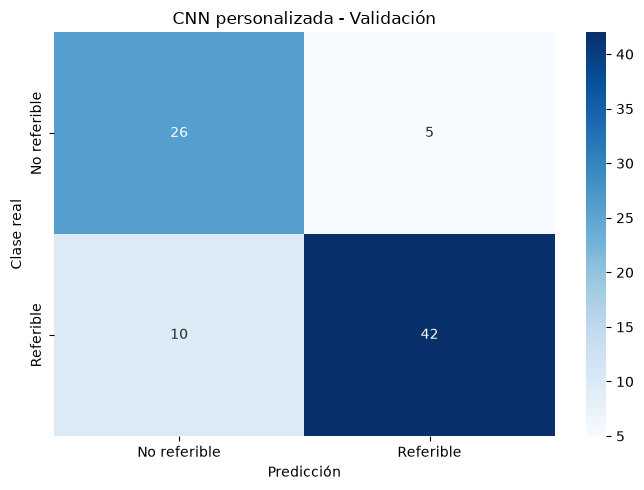

Total evaluado: 83


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
)

# Cargar el mejor modelo
best_cnn = keras.models.load_model(MODEL_PATH)

# Etiquetas reales
y_true = val_cnn["binary_label"].to_numpy(
    dtype=np.int32
)

# Probabilidades
y_probability = best_cnn.predict(
    val_ds,
    verbose=1,
).reshape(-1)

THRESHOLD = 0.50

y_pred = (
    y_probability >= THRESHOLD
).astype(int)

# Matriz
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1],
)

tn, fp, fn, tp = cm.ravel()

assert len(y_probability) == 83
assert cm.sum() == 83

# Métricas
results_cnn = pd.DataFrame([{
    "Modelo": "CNN personalizada",
    "Umbral": THRESHOLD,
    "Accuracy": accuracy_score(y_true, y_pred),
    "Sensibilidad": recall_score(y_true, y_pred),
    "Especificidad": tn / (tn + fp),
    "Precisión": precision_score(
        y_true, y_pred, zero_division=0
    ),
    "F1-score": f1_score(
        y_true, y_pred, zero_division=0
    ),
    "AUC-ROC": roc_auc_score(
        y_true, y_probability
    ),
    "AP": average_precision_score(
        y_true, y_probability
    ),
    "TN": tn,
    "FP": fp,
    "FN": fn,
    "TP": tp,
    "Total": cm.sum(),
}])

display(results_cnn.round(4))

# Visualización
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No referible", "Referible"],
    yticklabels=["No referible", "Referible"],
)

plt.title("CNN personalizada - Validación")
plt.xlabel("Predicción")
plt.ylabel("Clase real")
plt.tight_layout()
plt.show()

results_cnn.to_csv(
    OUTPUT_DIR / "metricas_cnn.csv",
    index=False,
)

print("Total evaluado:", cm.sum())

In [13]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from tensorflow import keras
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
    auc,
    balanced_accuracy_score,
    matthews_corrcoef,
    brier_score_loss,
)

from IPython.display import display

# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

SEED = 42
BATCH_SIZE = 16
SELECTED_THRESHOLD = 0.50

CLASS_NAMES = {
    0: "No referible",
    1: "Referible",
}

OUTPUT_DIR = Path("resultados_cnn_personalizada")

MODEL_PATH = (
    OUTPUT_DIR / "mejor_cnn_personalizada.keras"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert MODEL_PATH.exists(), (
    f"No se encontró el modelo: {MODEL_PATH}"
)

assert "val_cnn" in globals(), (
    "Primero debes ejecutar la auditoría "
    "que crea val_cnn."
)

# ============================================================
# 2. CARGAR MEJOR CNN
# ============================================================

best_cnn = keras.models.load_model(
    MODEL_PATH,
    compile=False,
)

print("Modelo cargado:", best_cnn.name)

# ============================================================
# 3. VERIFICAR VALIDACIÓN
# ============================================================

val_eval = val_cnn.copy().reset_index(drop=True)

assert len(val_eval) == 83, (
    f"Se esperaban 83 imágenes. "
    f"Encontradas: {len(val_eval)}"
)

assert val_eval["patient_id"].nunique() == 83

assert val_eval["binary_label"].isin([0, 1]).all()

assert val_eval["es_original"].all(), (
    "La evaluación contiene imágenes no originales."
)

image_paths = (
    val_eval["image_path"]
    .astype(str)
    .tolist()
)

missing_paths = [
    p for p in image_paths
    if not Path(p).is_file()
]

assert not missing_paths, (
    f"Faltan archivos: {missing_paths[:5]}"
)

# ============================================================
# 4. PREPARAR DATASET DE EVALUACIÓN
# ============================================================

input_shape = best_cnn.input_shape

IMG_HEIGHT = input_shape[1]
IMG_WIDTH = input_shape[2]

def load_eval_image(path):

    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False,
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMG_HEIGHT, IMG_WIDTH],
    )

    return tf.cast(image, tf.float32)

cnn_eval_ds = (
    tf.data.Dataset.from_tensor_slices(image_paths)
    .map(
        load_eval_image,
        num_parallel_calls=tf.data.AUTOTUNE,
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# La normalización ya está incluida
# en la capa Rescaling del modelo.

# ============================================================
# 5. PREDICCIONES
# ============================================================

cnn_y_true = val_eval["binary_label"].to_numpy(
    dtype=np.int32
)

cnn_y_probability = best_cnn.predict(
    cnn_eval_ds,
    verbose=1,
).reshape(-1)

assert len(cnn_y_probability) == len(cnn_y_true)
assert np.isfinite(cnn_y_probability).all()

assert np.all(
    (cnn_y_probability >= 0) &
    (cnn_y_probability <= 1)
)

cnn_y_pred = (
    cnn_y_probability >= SELECTED_THRESHOLD
).astype(np.int32)

# ============================================================
# 6. MATRIZ DE CONFUSIÓN
# ============================================================

cnn_cm = confusion_matrix(
    cnn_y_true,
    cnn_y_pred,
    labels=[0, 1],
)

tn, fp, fn, tp = cnn_cm.ravel()

assert cnn_cm.sum() == 83

# ============================================================
# 7. MÉTRICAS
# ============================================================

cnn_accuracy = accuracy_score(
    cnn_y_true, cnn_y_pred
)

cnn_precision = precision_score(
    cnn_y_true,
    cnn_y_pred,
    zero_division=0,
)

cnn_sensitivity = recall_score(
    cnn_y_true,
    cnn_y_pred,
    zero_division=0,
)

cnn_specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0 else np.nan
)

cnn_f1 = f1_score(
    cnn_y_true,
    cnn_y_pred,
    zero_division=0,
)

cnn_balanced_accuracy = balanced_accuracy_score(
    cnn_y_true,
    cnn_y_pred,
)

cnn_mcc = matthews_corrcoef(
    cnn_y_true,
    cnn_y_pred,
)

cnn_brier = brier_score_loss(
    cnn_y_true,
    cnn_y_probability,
)

cnn_npv = (
    tn / (tn + fn)
    if (tn + fn) > 0 else np.nan
)

cnn_fnr = (
    fn / (fn + tp)
    if (fn + tp) > 0 else np.nan
)

cnn_fpr = (
    fp / (fp + tn)
    if (fp + tn) > 0 else np.nan
)

# ============================================================
# 8. CURVAS ROC Y PR
# ============================================================

assert len(np.unique(cnn_y_true)) == 2, (
    "Se necesitan ambas clases para calcular AUC."
)

cnn_roc_auc = roc_auc_score(
    cnn_y_true,
    cnn_y_probability,
)

cnn_ap = average_precision_score(
    cnn_y_true,
    cnn_y_probability,
)

cnn_fpr_curve, cnn_tpr_curve, _ = roc_curve(
    cnn_y_true,
    cnn_y_probability,
)

cnn_precision_curve, cnn_recall_curve, _ = (
    precision_recall_curve(
        cnn_y_true,
        cnn_y_probability,
    )
)

cnn_pr_auc = auc(
    cnn_recall_curve,
    cnn_precision_curve,
)

# ============================================================
# 9. TABLA FINAL
# ============================================================

cnn_metrics_df = pd.DataFrame([{
    "Modelo": "CNN personalizada",
    "Umbral": SELECTED_THRESHOLD,
    "Accuracy": cnn_accuracy,
    "Sensibilidad": cnn_sensitivity,
    "Especificidad": cnn_specificity,
    "Precisión": cnn_precision,
    "F1-score": cnn_f1,
    "AUC-ROC": cnn_roc_auc,
    "AUC-PR": cnn_pr_auc,
    "Average Precision": cnn_ap,
    "Brier Score": cnn_brier,
    "Balanced Accuracy": cnn_balanced_accuracy,
    "MCC": cnn_mcc,
    "VPN": cnn_npv,
    "FNR": cnn_fnr,
    "FPR": cnn_fpr,
    "TN": tn,
    "FP": fp,
    "FN": fn,
    "TP": tp,
    "Total evaluado": cnn_cm.sum(),
}])

print("\n===== MÉTRICAS CNN PERSONALIZADA =====")
display(cnn_metrics_df.round(4))

print("\n===== REPORTE POR CLASE =====")

print(
    classification_report(
        cnn_y_true,
        cnn_y_pred,
        labels=[0, 1],
        target_names=[
            CLASS_NAMES[0],
            CLASS_NAMES[1],
        ],
        digits=4,
        zero_division=0,
    )
)

print("\n===== VERIFICACIÓN =====")
print("Pacientes:", val_eval["patient_id"].nunique())
print("Imágenes:", len(cnn_y_true))
print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)
print("Total matriz:", cnn_cm.sum())

# ============================================================
# 10. GUARDAR RESULTADOS
# ============================================================

cnn_metrics_df.to_csv(
    OUTPUT_DIR / "metricas_completas_cnn.csv",
    index=False,
)

cnn_predictions_df = val_eval[
    ["patient_id", "image_path", "binary_label"]
].copy()

cnn_predictions_df["probabilidad"] = (
    cnn_y_probability
)

cnn_predictions_df["prediccion"] = cnn_y_pred

cnn_predictions_df["resultado"] = np.select(
    [
        (cnn_y_true == 0) & (cnn_y_pred == 0),
        (cnn_y_true == 0) & (cnn_y_pred == 1),
        (cnn_y_true == 1) & (cnn_y_pred == 0),
        (cnn_y_true == 1) & (cnn_y_pred == 1),
    ],
    ["TN", "FP", "FN", "TP"],
    default="Desconocido",
)

cnn_predictions_df.to_csv(
    OUTPUT_DIR / "predicciones_cnn.csv",
    index=False,
)

print("\nMétricas y predicciones guardadas.")

Modelo cargado: CNN_Personalizada
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 72ms/step

===== MÉTRICAS CNN PERSONALIZADA =====


,Modelo,Umbral,Accuracy,Sensibilidad,Especificidad,Precisión,F1-score,AUC-ROC,AUC-PR,Average Precision,...,Balanced Accuracy,MCC,VPN,FNR,FPR,TN,FP,FN,TP,Total evaluado
0,CNN personalizada,0.5,0.8193,0.8077,0.8387,0.8936,0.8485,0.8958,0.9336,0.9344,...,0.8232,0.6309,0.7222,0.1923,0.1613,26,5,10,42,83



===== REPORTE POR CLASE =====
              precision    recall  f1-score   support

No referible     0.7222    0.8387    0.7761        31
   Referible     0.8936    0.8077    0.8485        52

    accuracy                         0.8193        83
   macro avg     0.8079    0.8232    0.8123        83
weighted avg     0.8296    0.8193    0.8215        83


===== VERIFICACIÓN =====
Pacientes: 83
Imágenes: 83
TN: 26
FP: 5
FN: 10
TP: 42
Total matriz: 83

Métricas y predicciones guardadas.


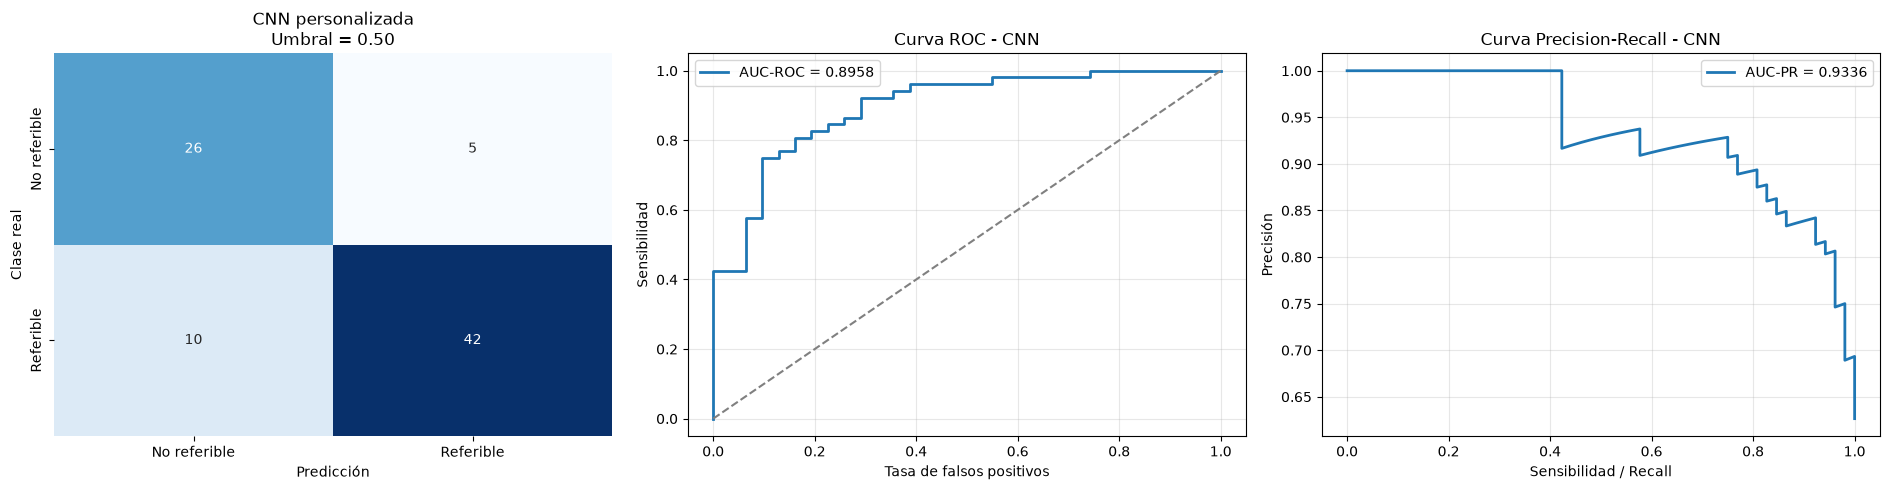

In [14]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(19, 5),
)

# ============================================================
# MATRIZ DE CONFUSIÓN
# ============================================================

sns.heatmap(
    cnn_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=[
        CLASS_NAMES[0],
        CLASS_NAMES[1],
    ],
    yticklabels=[
        CLASS_NAMES[0],
        CLASS_NAMES[1],
    ],
    ax=axes[0],
)

axes[0].set_title(
    f"CNN personalizada\n"
    f"Umbral = {SELECTED_THRESHOLD:.2f}"
)

axes[0].set_xlabel("Predicción")
axes[0].set_ylabel("Clase real")

# ============================================================
# CURVA ROC
# ============================================================

axes[1].plot(
    cnn_fpr_curve,
    cnn_tpr_curve,
    linewidth=2,
    label=f"AUC-ROC = {cnn_roc_auc:.4f}",
)

axes[1].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
)

axes[1].set_title("Curva ROC - CNN")
axes[1].set_xlabel("Tasa de falsos positivos")
axes[1].set_ylabel("Sensibilidad")
axes[1].legend()
axes[1].grid(alpha=0.3)

# ============================================================
# CURVA PRECISION-RECALL
# ============================================================

axes[2].plot(
    cnn_recall_curve,
    cnn_precision_curve,
    linewidth=2,
    label=f"AUC-PR = {cnn_pr_auc:.4f}",
)

axes[2].set_title(
    "Curva Precision-Recall - CNN"
)

axes[2].set_xlabel("Sensibilidad / Recall")
axes[2].set_ylabel("Precisión")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "graficas_evaluacion_cnn.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

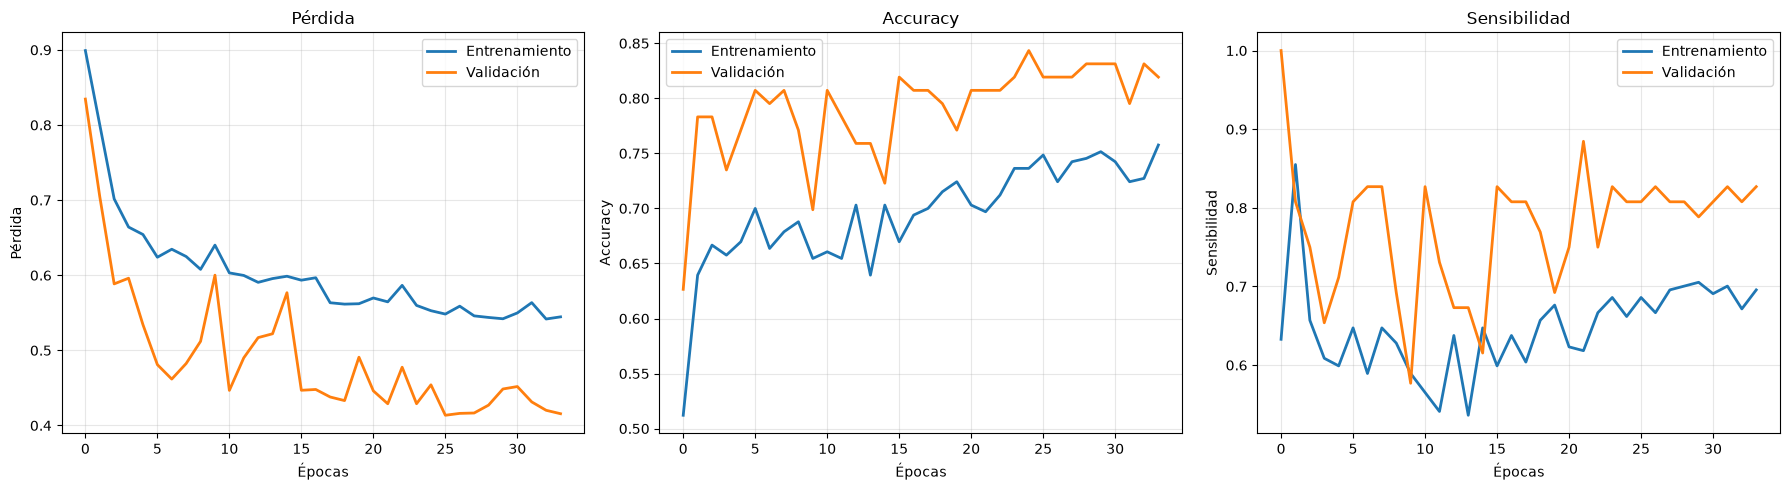

In [15]:
# ============================================================
# RECUPERAR HISTORIAL DE ENTRENAMIENTO
# ============================================================

history_path = OUTPUT_DIR / "historial.csv"

if history_path.exists():

    history_df = pd.read_csv(history_path)

elif "history_cnn" in globals():

    history_df = pd.DataFrame(
        history_cnn.history
    )

else:
    raise FileNotFoundError(
        "No se encontró el historial de entrenamiento."
    )

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5),
)

metricas = [
    ("loss", "val_loss", "Pérdida"),
    ("accuracy", "val_accuracy", "Accuracy"),
    ("recall", "val_recall", "Sensibilidad"),
]

for ax, (train_metric, val_metric, titulo) in zip(
    axes, metricas
):

    if train_metric in history_df.columns:
        ax.plot(
            history_df[train_metric],
            label="Entrenamiento",
            linewidth=2,
        )

    if val_metric in history_df.columns:
        ax.plot(
            history_df[val_metric],
            label="Validación",
            linewidth=2,
        )

    ax.set_title(titulo)
    ax.set_xlabel("Épocas")
    ax.set_ylabel(titulo)
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "historial_entrenamiento_cnn.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [16]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from tensorflow import keras
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
    auc,
    balanced_accuracy_score,
    matthews_corrcoef,
    brier_score_loss,
)

from IPython.display import display

# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

SEED = 42
BATCH_SIZE = 16
SELECTED_THRESHOLD = 0.50

CLASS_NAMES = {
    0: "No referible",
    1: "Referible",
}

OUTPUT_DIR = Path("resultados_cnn_personalizada")

MODEL_PATH = (
    OUTPUT_DIR / "mejor_cnn_personalizada.keras"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert MODEL_PATH.is_file(), (
    f"No se encontró el modelo: {MODEL_PATH}"
)

assert "val_cnn" in globals(), (
    "Primero ejecuta la auditoría que crea val_cnn."
)

# ============================================================
# 2. CARGAR MEJOR MODELO
# ============================================================

best_cnn = keras.models.load_model(
    MODEL_PATH,
    compile=False,
)

print("Modelo cargado:", best_cnn.name)

# ============================================================
# 3. VERIFICAR DATOS DE VALIDACIÓN
# ============================================================

val_eval = val_cnn.copy().reset_index(drop=True)

assert len(val_eval) == 83, (
    f"Se esperaban 83 imágenes: {len(val_eval)}"
)

assert val_eval["patient_id"].nunique() == 83

assert val_eval["binary_label"].isin([0, 1]).all()

assert val_eval["es_original"].all(), (
    "Hay imágenes no originales en validación."
)

paths = val_eval["image_path"].astype(str).tolist()

missing = [
    path for path in paths
    if not Path(path).is_file()
]

assert not missing, (
    f"Archivos no encontrados: {missing[:5]}"
)

print("Imágenes:", len(val_eval))
print("Pacientes:", val_eval["patient_id"].nunique())

# ============================================================
# 4. PREPARAR IMÁGENES
# ============================================================

input_shape = best_cnn.input_shape

IMG_HEIGHT = input_shape[1]
IMG_WIDTH = input_shape[2]

assert IMG_HEIGHT is not None
assert IMG_WIDTH is not None

# El modelo entrenado tiene una capa Rescaling.
# Por eso no dividimos nuevamente entre 255.

def load_eval_image(path):

    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False,
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMG_HEIGHT, IMG_WIDTH],
    )

    return tf.cast(image, tf.float32)


cnn_eval_ds = (
    tf.data.Dataset.from_tensor_slices(paths)
    .map(
        load_eval_image,
        num_parallel_calls=tf.data.AUTOTUNE,
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# ============================================================
# 5. GENERAR PREDICCIONES
# ============================================================

cnn_y_true = (
    val_eval["binary_label"]
    .to_numpy(dtype=np.int32)
)

cnn_y_probability = best_cnn.predict(
    cnn_eval_ds,
    verbose=1,
).reshape(-1)

assert len(cnn_y_true) == len(cnn_y_probability)
assert len(cnn_y_true) == 83
assert np.isfinite(cnn_y_probability).all()

assert np.all(
    (cnn_y_probability >= 0) &
    (cnn_y_probability <= 1)
)

cnn_y_pred = (
    cnn_y_probability >= SELECTED_THRESHOLD
).astype(np.int32)

# ============================================================
# 6. MATRIZ DE CONFUSIÓN
# ============================================================

cnn_cm = confusion_matrix(
    cnn_y_true,
    cnn_y_pred,
    labels=[0, 1],
)

tn, fp, fn, tp = cnn_cm.ravel()

assert cnn_cm.sum() == 83

# ============================================================
# 7. CALCULAR MÉTRICAS
# ============================================================

assert len(np.unique(cnn_y_true)) == 2, (
    "Se necesitan ambas clases para AUC."
)

cnn_accuracy = accuracy_score(
    cnn_y_true, cnn_y_pred
)

cnn_precision = precision_score(
    cnn_y_true, cnn_y_pred,
    zero_division=0,
)

cnn_sensitivity = recall_score(
    cnn_y_true, cnn_y_pred,
    zero_division=0,
)

cnn_specificity = (
    tn / (tn + fp)
    if tn + fp > 0 else np.nan
)

cnn_f1 = f1_score(
    cnn_y_true, cnn_y_pred,
    zero_division=0,
)

cnn_roc_auc = roc_auc_score(
    cnn_y_true, cnn_y_probability
)

cnn_average_precision = average_precision_score(
    cnn_y_true, cnn_y_probability
)

cnn_brier = brier_score_loss(
    cnn_y_true, cnn_y_probability
)

cnn_balanced_accuracy = balanced_accuracy_score(
    cnn_y_true, cnn_y_pred
)

cnn_mcc = matthews_corrcoef(
    cnn_y_true, cnn_y_pred
)

cnn_npv = (
    tn / (tn + fn)
    if tn + fn > 0 else np.nan
)

cnn_fnr = (
    fn / (fn + tp)
    if fn + tp > 0 else np.nan
)

# ============================================================
# 8. CALCULAR CURVAS
# ============================================================

cnn_fpr_curve, cnn_tpr_curve, _ = roc_curve(
    cnn_y_true,
    cnn_y_probability,
)

cnn_precision_curve, cnn_recall_curve, _ = (
    precision_recall_curve(
        cnn_y_true,
        cnn_y_probability,
    )
)

cnn_pr_auc = auc(
    cnn_recall_curve,
    cnn_precision_curve,
)

# ============================================================
# 9. TABLA FINAL DE MÉTRICAS
# ============================================================

cnn_metrics_df = pd.DataFrame([{
    "Modelo": "CNN personalizada",
    "Umbral": SELECTED_THRESHOLD,
    "Accuracy": cnn_accuracy,
    "Sensibilidad": cnn_sensitivity,
    "Especificidad": cnn_specificity,
    "Precisión": cnn_precision,
    "F1-score": cnn_f1,
    "AUC-ROC": cnn_roc_auc,
    "AUC-PR": cnn_pr_auc,
    "Average Precision": cnn_average_precision,
    "Brier Score": cnn_brier,
    "Balanced Accuracy": cnn_balanced_accuracy,
    "MCC": cnn_mcc,
    "VPN": cnn_npv,
    "FNR": cnn_fnr,
    "TN": tn,
    "FP": fp,
    "FN": fn,
    "TP": tp,
    "Total": cnn_cm.sum(),
}])

print("\n===== MÉTRICAS CNN PERSONALIZADA =====")

display(cnn_metrics_df.round(4))

print("\n===== REPORTE DE CLASIFICACIÓN =====")

print(
    classification_report(
        cnn_y_true,
        cnn_y_pred,
        labels=[0, 1],
        target_names=[
            "No referible",
            "Referible",
        ],
        digits=4,
        zero_division=0,
    )
)

print("\n===== MATRIZ DE CONFUSIÓN =====")
print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

print("\nTOTAL EVALUADO:", cnn_cm.sum())

# ============================================================
# 10. GUARDAR PREDICCIONES
# ============================================================

cnn_predictions_df = val_eval[
    ["patient_id", "image_path", "binary_label"]
].copy()

cnn_predictions_df["probabilidad"] = (
    cnn_y_probability
)

cnn_predictions_df["prediccion"] = cnn_y_pred

cnn_predictions_df["resultado"] = np.select(
    [
        (cnn_y_true == 0) & (cnn_y_pred == 0),
        (cnn_y_true == 0) & (cnn_y_pred == 1),
        (cnn_y_true == 1) & (cnn_y_pred == 0),
        (cnn_y_true == 1) & (cnn_y_pred == 1),
    ],
    ["TN", "FP", "FN", "TP"],
    default="Sin clasificar",
)

cnn_metrics_df.to_csv(
    OUTPUT_DIR / "metricas_completas_cnn.csv",
    index=False,
)

cnn_predictions_df.to_csv(
    OUTPUT_DIR / "predicciones_cnn.csv",
    index=False,
)

print("\nResultados guardados correctamente.")

Modelo cargado: CNN_Personalizada
Imágenes: 83
Pacientes: 83
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 79ms/step

===== MÉTRICAS CNN PERSONALIZADA =====


,Modelo,Umbral,Accuracy,Sensibilidad,Especificidad,Precisión,F1-score,AUC-ROC,AUC-PR,Average Precision,Brier Score,Balanced Accuracy,MCC,VPN,FNR,TN,FP,FN,TP,Total
0,CNN personalizada,0.5,0.8193,0.8077,0.8387,0.8936,0.8485,0.8958,0.9336,0.9344,0.1272,0.8232,0.6309,0.7222,0.1923,26,5,10,42,83



===== REPORTE DE CLASIFICACIÓN =====
              precision    recall  f1-score   support

No referible     0.7222    0.8387    0.7761        31
   Referible     0.8936    0.8077    0.8485        52

    accuracy                         0.8193        83
   macro avg     0.8079    0.8232    0.8123        83
weighted avg     0.8296    0.8193    0.8215        83


===== MATRIZ DE CONFUSIÓN =====
TN: 26
FP: 5
FN: 10
TP: 42

TOTAL EVALUADO: 83

Resultados guardados correctamente.


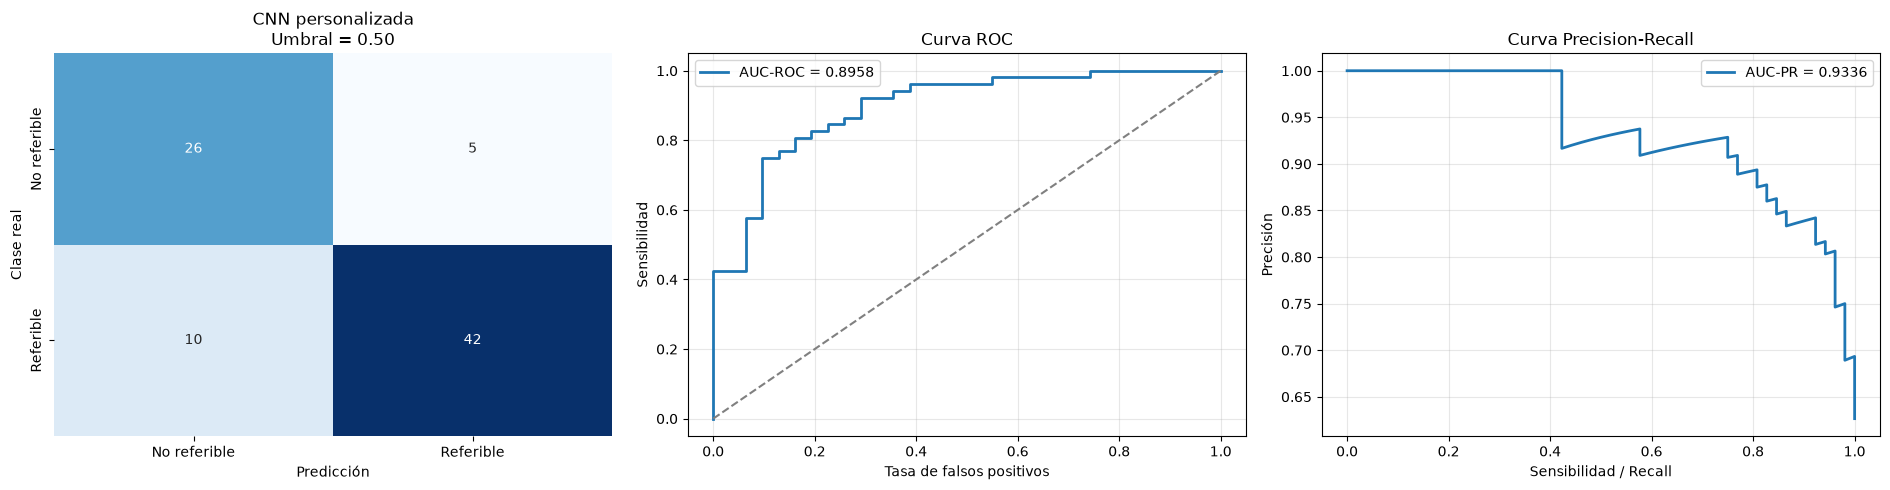

In [17]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(19, 5),
)

# ============================================================
# MATRIZ DE CONFUSIÓN
# ============================================================

sns.heatmap(
    cnn_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=[
        "No referible",
        "Referible",
    ],
    yticklabels=[
        "No referible",
        "Referible",
    ],
    ax=axes[0],
)

axes[0].set_title(
    f"CNN personalizada\n"
    f"Umbral = {SELECTED_THRESHOLD:.2f}"
)

axes[0].set_xlabel("Predicción")
axes[0].set_ylabel("Clase real")

# ============================================================
# CURVA ROC
# ============================================================

axes[1].plot(
    cnn_fpr_curve,
    cnn_tpr_curve,
    linewidth=2,
    label=f"AUC-ROC = {cnn_roc_auc:.4f}",
)

axes[1].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
)

axes[1].set_title("Curva ROC")
axes[1].set_xlabel("Tasa de falsos positivos")
axes[1].set_ylabel("Sensibilidad")
axes[1].legend()
axes[1].grid(alpha=0.3)

# ============================================================
# CURVA PRECISION-RECALL
# ============================================================

axes[2].plot(
    cnn_recall_curve,
    cnn_precision_curve,
    linewidth=2,
    label=f"AUC-PR = {cnn_pr_auc:.4f}",
)

axes[2].set_title("Curva Precision-Recall")
axes[2].set_xlabel("Sensibilidad / Recall")
axes[2].set_ylabel("Precisión")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "evaluacion_completa_cnn.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

Capa seleccionada: conv2d_3


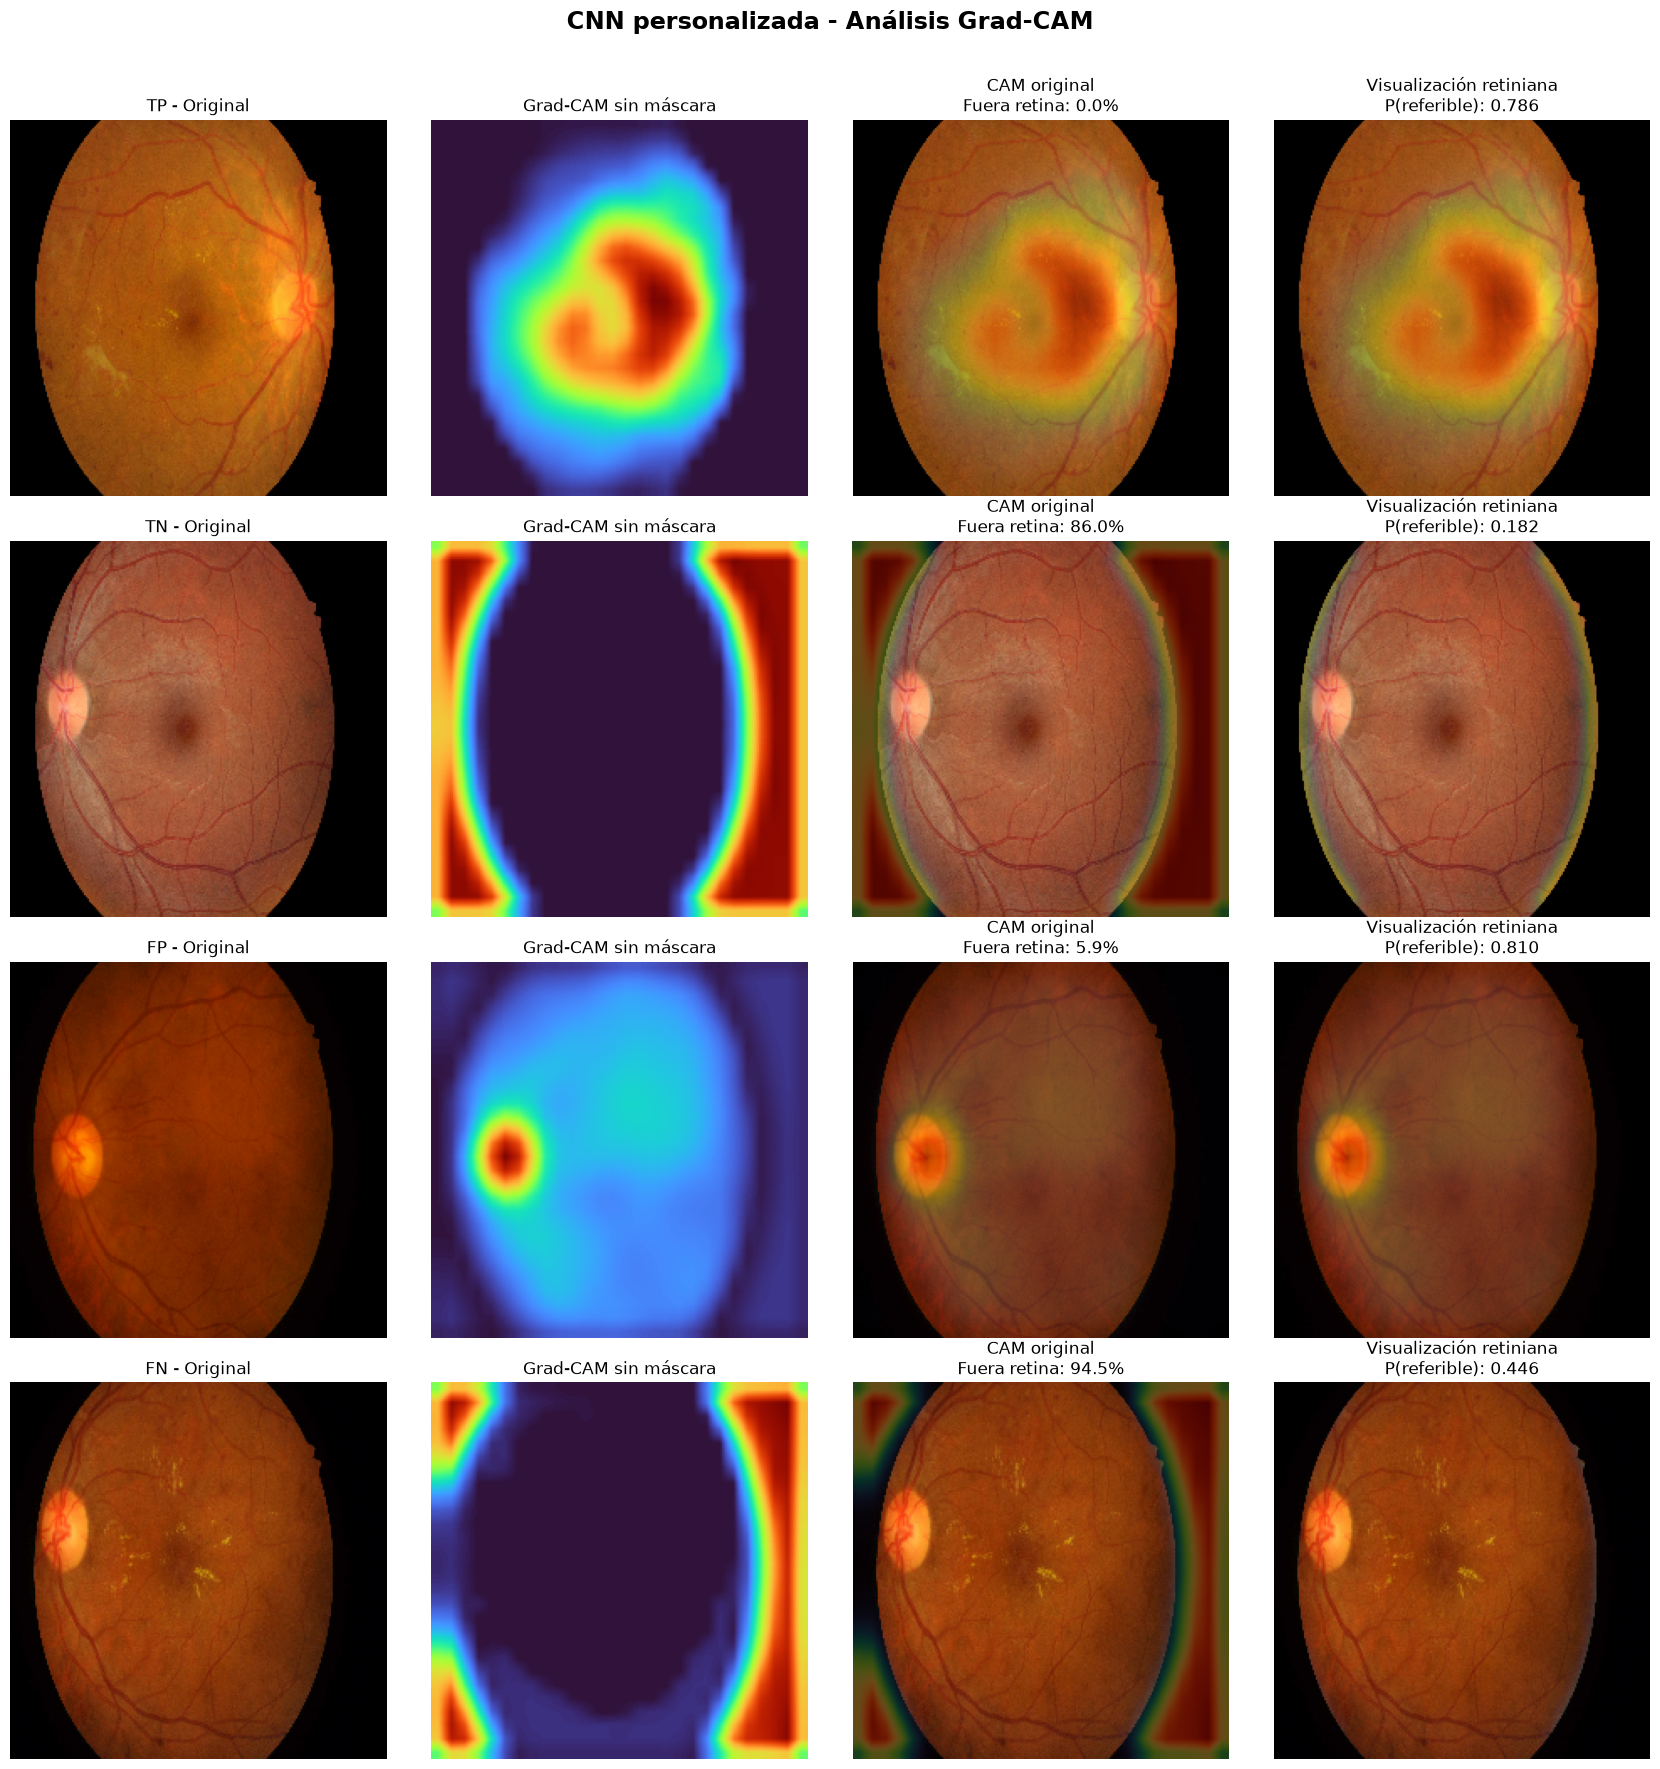

,Caso,Paciente,Real,Predicción,Probabilidad,Activación fuera de retina (%)
0,TP,IDRiD_254,1,1,0.786,0.003000
1,TN,IDRiD_209,0,0,0.182,85.964996
2,FP,IDRiD_154,0,1,0.810,5.850000
3,FN,IDRiD_343,1,0,0.446,94.509003



Grad-CAM generado correctamente.


In [19]:
# ============================================================
# GRAD-CAM MEJORADO - CNN PERSONALIZADA
# TP / TN / FP / FN
# ============================================================

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from pathlib import Path
from scipy import ndimage
from tensorflow import keras

# ============================================================
# CONFIGURACIÓN
# ============================================================

OUTPUT_DIR = Path("resultados_cnn_personalizada")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
CONV_INDEX = -1   # -1 última Conv2D; -2 penúltima

# ============================================================
# 1. IDENTIFICAR CAPA CONVOLUCIONAL
# ============================================================

conv_layers = [
    layer
    for layer in best_cnn.layers
    if isinstance(layer, keras.layers.Conv2D)
]

if not conv_layers:
    raise ValueError("No se encontraron capas Conv2D.")

last_conv = conv_layers[CONV_INDEX]

print("Capa seleccionada:", last_conv.name)

grad_model = keras.Model(
    inputs=best_cnn.inputs,
    outputs=[
        last_conv.output,
        best_cnn.output,
    ],
)

# ============================================================
# 2. CALCULAR GRAD-CAM CON LOGITS
# ============================================================

def improved_gradcam(image_batch, target_class):

    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(
            image_batch,
            training=False,
        )

        probability = predictions[:, 0]

        probability = tf.clip_by_value(
            probability,
            1e-6,
            1.0 - 1e-6,
        )

        logit = tf.math.log(
            probability / (1.0 - probability)
        )

        if target_class == 1:
            score = logit
        elif target_class == 0:
            score = -logit
        else:
            raise ValueError("Clase inválida.")

    grads = tape.gradient(
        score,
        conv_outputs,
    )

    if grads is None:
        raise ValueError(
            "No fue posible calcular los gradientes."
        )

    weights = tf.reduce_mean(
        grads,
        axis=(1, 2),
    )

    cam = tf.reduce_sum(
        conv_outputs * weights[:, None, None, :],
        axis=-1,
    )

    cam = tf.nn.relu(cam[0])

    cam_max = tf.reduce_max(cam)

    cam = cam / (cam_max + 1e-8)

    return cam.numpy()

# ============================================================
# 3. IDENTIFICAR REGIÓN RETINIANA
# ============================================================

def retinal_mask(image):

    rgb = np.clip(
        image / 255.0,
        0.0,
        1.0,
    )

    # Separación aproximada del fondo negro
    mask = np.max(rgb, axis=-1) > 0.09

    mask = ndimage.binary_opening(
        mask,
        iterations=2,
    )

    mask = ndimage.binary_fill_holes(mask)

    # Conservar la región conectada más grande
    labeled, count = ndimage.label(mask)

    if count == 0:
        raise ValueError(
            "No se identificó el fondo de ojo."
        )

    sizes = np.bincount(labeled.ravel())
    sizes[0] = 0

    largest = np.argmax(sizes)

    mask = labeled == largest

    return mask.astype(np.float32)

# ============================================================
# 4. PREPARAR MAPAS
# ============================================================

def prepare_maps(image, heatmap):

    height, width = image.shape[:2]

    heatmap = tf.image.resize(
        heatmap[..., None],
        [height, width],
    ).numpy()[..., 0]

    heatmap = np.clip(heatmap, 0.0, 1.0)

    mask = retinal_mask(image)

    # CAM original: NO se modifica para el diagnóstico
    raw_cam = heatmap.copy()

    # CAM limitado a retina: solo visualización
    masked_cam = heatmap * mask

    return raw_cam, masked_cam, mask

# ============================================================
# 5. SUPERPOSICIÓN
# ============================================================

def overlay_gradcam(image, heatmap):

    original = np.clip(
        image / 255.0,
        0.0,
        1.0,
    )

    colored = plt.get_cmap("turbo")(
        heatmap
    )[..., :3]

    # Transparencia proporcional a la activación
    alpha = 0.60 * heatmap[..., None]

    overlay = (
        original * (1.0 - alpha)
        + colored * alpha
    )

    return np.clip(overlay, 0.0, 1.0)

# ============================================================
# 6. GENERAR LOS CUATRO CASOS
# ============================================================

case_types = ["TP", "TN", "FP", "FN"]

fig, axes = plt.subplots(
    4,
    4,
    figsize=(17, 18),
)

diagnostico = []

for row, case_type in enumerate(case_types):

    matches = cnn_predictions_df[
        cnn_predictions_df["resultado"] == case_type
    ]

    if matches.empty:

        for ax in axes[row]:
            ax.axis("off")

        axes[row, 1].text(
            0.5, 0.5,
            f"No hay casos {case_type}",
            ha="center",
            va="center",
        )

        continue

    # Muestra reproducible, sin escoger
    # manualmente la imagen más favorable.
    case = matches.sample(
        n=1,
        random_state=SEED,
    ).iloc[0]

    image_path = case["image_path"]

    true_label = int(case["binary_label"])
    pred_label = int(case["prediccion"])

    probability = float(case["probabilidad"])

    image = load_eval_image(
        tf.constant(str(image_path))
    )

    image_batch = tf.expand_dims(image, 0)

    image_np = image.numpy()

    heatmap = improved_gradcam(
        image_batch,
        target_class=pred_label,
    )

    raw_cam, masked_cam, mask = prepare_maps(
        image_np,
        heatmap,
    )

    raw_overlay = overlay_gradcam(
        image_np,
        raw_cam,
    )

    masked_overlay = overlay_gradcam(
        image_np,
        masked_cam,
    )

    # Cuantificar activación fuera de retina
    total_activation = raw_cam.sum()

    outside_activation = (
        raw_cam * (1.0 - mask)
    ).sum()

    outside_percent = (
        100.0 * outside_activation /
        (total_activation + 1e-8)
    )

    diagnostico.append({
        "Caso": case_type,
        "Paciente": case["patient_id"],
        "Real": true_label,
        "Predicción": pred_label,
        "Probabilidad": probability,
        "Activación fuera de retina (%)": outside_percent,
    })

    # Imagen original
    axes[row, 0].imshow(
        np.clip(image_np / 255.0, 0, 1)
    )

    axes[row, 0].set_title(
        f"{case_type} - Original"
    )

    # Grad-CAM real
    axes[row, 1].imshow(
        raw_cam,
        cmap="turbo",
        vmin=0,
        vmax=1,
    )

    axes[row, 1].set_title(
        "Grad-CAM sin máscara"
    )

    # Superposición original
    axes[row, 2].imshow(raw_overlay)

    axes[row, 2].set_title(
        f"CAM original\n"
        f"Fuera retina: {outside_percent:.1f}%"
    )

    # Superposición limitada a retina
    axes[row, 3].imshow(masked_overlay)

    axes[row, 3].set_title(
        f"Visualización retiniana\n"
        f"P(referible): {probability:.3f}"
    )

    for ax in axes[row]:
        ax.axis("off")

plt.suptitle(
    "CNN personalizada - Análisis Grad-CAM",
    fontsize=17,
    fontweight="bold",
)

plt.tight_layout(
    rect=[0, 0, 1, 0.97]
)

plt.savefig(
    OUTPUT_DIR / "gradcam_cnn_mejorado.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

# ============================================================
# 7. INFORME
# ============================================================

import pandas as pd

diagnostico_df = pd.DataFrame(diagnostico)

display(diagnostico_df.round(3))

diagnostico_df.to_csv(
    OUTPUT_DIR / "auditoria_gradcam.csv",
    index=False,
)

print("\nGrad-CAM generado correctamente.")

In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from pathlib import Path
from scipy import ndimage
from tensorflow import keras
from matplotlib.patches import Rectangle

# ============================================================
# CONFIGURACIÓN
# ============================================================

OUTPUT_DIR = Path("resultados_cnn_personalizada")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
CONV_INDEX = -1          # última capa Conv2D
THRESHOLD_MODE = "percentile"   # "percentile" o "absolute"
PERCENTILE = 90          # top 10% activación dentro de retina
ABS_THRESHOLD = 0.60     # si quieres umbral absoluto
MIN_REGION_SIZE = 40     # tamaño mínimo de zona relevante

# ============================================================
# 1. IDENTIFICAR CAPA CONVOLUCIONAL
# ============================================================

conv_layers = [
    layer for layer in best_cnn.layers
    if isinstance(layer, keras.layers.Conv2D)
]

if not conv_layers:
    raise ValueError("No se encontraron capas Conv2D en el modelo.")

selected_conv = conv_layers[CONV_INDEX]

print("Capa seleccionada para Grad-CAM:", selected_conv.name)

grad_model = keras.Model(
    inputs=best_cnn.inputs,
    outputs=[
        selected_conv.output,
        best_cnn.output,
    ],
)

# ============================================================
# 2. FUNCIÓN GRAD-CAM
# ============================================================

def gradcam_for_class(image_batch, target_class):

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(
            image_batch,
            training=False,
        )

        prob = predictions[:, 0]
        prob = tf.clip_by_value(prob, 1e-6, 1.0 - 1e-6)

        logit = tf.math.log(prob / (1.0 - prob))

        if target_class == 1:
            score = logit
        elif target_class == 0:
            score = -logit
        else:
            raise ValueError("target_class debe ser 0 o 1")

    grads = tape.gradient(score, conv_outputs)

    if grads is None:
        raise ValueError("No se pudieron calcular gradientes.")

    weights = tf.reduce_mean(grads, axis=(1, 2))

    cam = tf.reduce_sum(
        conv_outputs * weights[:, None, None, :],
        axis=-1,
    )

    cam = tf.nn.relu(cam[0])
    cam = cam / (tf.reduce_max(cam) + 1e-8)

    return cam.numpy()

# ============================================================
# 3. MÁSCARA DE RETINA
# ============================================================

def build_retina_mask(image_np):

    rgb = np.clip(image_np / 255.0, 0.0, 1.0)

    mask = np.max(rgb, axis=-1) > 0.08

    mask = ndimage.binary_opening(mask, iterations=2)
    mask = ndimage.binary_closing(mask, iterations=2)
    mask = ndimage.binary_fill_holes(mask)

    labeled, n = ndimage.label(mask)

    if n == 0:
        raise ValueError("No se pudo detectar la retina.")

    sizes = np.bincount(labeled.ravel())
    sizes[0] = 0
    largest = np.argmax(sizes)

    mask = (labeled == largest).astype(np.uint8)

    return mask

# ============================================================
# 4. REDIMENSIONAR CAM Y LIMITARLA A RETINA
# ============================================================

def resize_and_mask_cam(image_np, cam_small, retina_mask):

    h, w = image_np.shape[:2]

    cam_resized = tf.image.resize(
        cam_small[..., np.newaxis],
        [h, w]
    ).numpy()[..., 0]

    cam_resized = np.clip(cam_resized, 0.0, 1.0)

    cam_masked = cam_resized * retina_mask

    # normalizar dentro de retina
    max_inside = cam_masked.max()
    if max_inside > 0:
        cam_masked = cam_masked / max_inside

    return cam_resized, cam_masked

# ============================================================
# 5. EXTRAER ZONA RELEVANTE
# ============================================================

def extract_relevant_region(cam_masked, retina_mask):

    inside_values = cam_masked[retina_mask > 0]

    if inside_values.size == 0:
        raise ValueError("No hay activaciones dentro de la retina.")

    if THRESHOLD_MODE == "percentile":
        threshold = np.percentile(inside_values, PERCENTILE)
    else:
        threshold = ABS_THRESHOLD

    relevant = (cam_masked >= threshold).astype(np.uint8)
    relevant = relevant * retina_mask

    # limpiar ruido
    labeled, n = ndimage.label(relevant)

    if n == 0:
        return relevant, None, None, None, threshold

    slices = ndimage.find_objects(labeled)

    best_label = None
    best_score = -1

    for i, slc in enumerate(slices, start=1):
        region = (labeled == i)
        area = region.sum()

        if area < MIN_REGION_SIZE:
            continue

        score = cam_masked[region].sum()

        if score > best_score:
            best_score = score
            best_label = i

    if best_label is None:
        return relevant, None, None, None, threshold

    best_region = (labeled == best_label).astype(np.uint8)

    coords = np.argwhere(best_region > 0)

    y_min, x_min = coords.min(axis=0)
    y_max, x_max = coords.max(axis=0)

    centroid_y, centroid_x = coords.mean(axis=0)

    bbox = (x_min, y_min, x_max - x_min, y_max - y_min)
    centroid = (centroid_x, centroid_y)

    return best_region, bbox, centroid, coords, threshold

# ============================================================
# 6. SUPERPOSICIÓN
# ============================================================

def overlay_cam(image_np, cam_masked):

    img = np.clip(image_np / 255.0, 0.0, 1.0)

    cmap = plt.get_cmap("turbo")
    heat_rgb = cmap(cam_masked)[..., :3]

    alpha = 0.65 * cam_masked[..., None]

    overlay = img * (1 - alpha) + heat_rgb * alpha
    overlay = np.clip(overlay, 0.0, 1.0)

    return overlay

# ============================================================
# 7. FUNCIÓN PRINCIPAL PARA UN CASO
# ============================================================

def show_masked_gradcam_case(case_type="TP"):

    subset = cnn_predictions_df[
        cnn_predictions_df["resultado"] == case_type
    ]

    if subset.empty:
        print(f"No hay casos {case_type}.")
        return

    # toma un ejemplo reproducible
    case = subset.sample(n=1, random_state=SEED).iloc[0]

    image_path = case["image_path"]
    true_label = int(case["binary_label"])
    pred_label = int(case["prediccion"])
    prob = float(case["probabilidad"])
    patient_id = case["patient_id"]

    image = load_eval_image(tf.constant(str(image_path)))
    image_batch = tf.expand_dims(image, axis=0)
    image_np = image.numpy()

    cam_small = gradcam_for_class(
        image_batch=image_batch,
        target_class=pred_label,
    )

    retina_mask = build_retina_mask(image_np)

    cam_full, cam_masked = resize_and_mask_cam(
        image_np=image_np,
        cam_small=cam_small,
        retina_mask=retina_mask,
    )

    best_region, bbox, centroid, coords, threshold = (
        extract_relevant_region(cam_masked, retina_mask)
    )

    overlay = overlay_cam(image_np, cam_masked)

    # imagen con todo marcado
    fig, axes = plt.subplots(1, 4, figsize=(18, 5))

    # 1) original
    axes[0].imshow(np.clip(image_np / 255.0, 0, 1))
    axes[0].set_title(
        f"{case_type} - Original\nPaciente: {patient_id}"
    )
    axes[0].axis("off")

    # 2) máscara de retina
    axes[1].imshow(retina_mask, cmap="gray")
    axes[1].set_title("Máscara de retina")
    axes[1].axis("off")

    # 3) heatmap dentro de retina
    axes[2].imshow(np.clip(image_np / 255.0, 0, 1))
    axes[2].imshow(
        cam_masked,
        cmap="turbo",
        alpha=0.65,
        vmin=0,
        vmax=1,
    )

    if best_region is not None:
        axes[2].contour(
            best_region,
            levels=[0.5],
            colors="lime",
            linewidths=2,
        )

        if centroid is not None:
            cx, cy = centroid
            axes[2].plot(
                cx, cy,
                marker="x",
                markersize=10,
                markeredgewidth=2,
                color="white",
            )

    axes[2].set_title(
        f"Heatmap dentro de retina\nUmbral: {threshold:.3f}"
    )
    axes[2].axis("off")

    # 4) overlay final con zona relevante marcada
    axes[3].imshow(overlay)

    if best_region is not None:
        axes[3].contour(
            best_region,
            levels=[0.5],
            colors="yellow",
            linewidths=2,
        )

        if bbox is not None:
            x, y, w, h = bbox
            rect = Rectangle(
                (x, y),
                w,
                h,
                fill=False,
                edgecolor="cyan",
                linewidth=2,
            )
            axes[3].add_patch(rect)

        if centroid is not None:
            cx, cy = centroid
            axes[3].plot(
                cx, cy,
                marker="o",
                markersize=6,
                color="red",
            )

    axes[3].set_title(
        f"Real: {true_label} | Pred: {pred_label}\n"
        f"P(referible): {prob:.4f}"
    )
    axes[3].axis("off")

    plt.tight_layout()
    plt.show()

    # Resumen textual
    print("===== RESUMEN DEL CASO =====")
    print("Caso:", case_type)
    print("Paciente:", patient_id)
    print("Ruta:", image_path)
    print("Real:", true_label)
    print("Predicción:", pred_label)
    print("Probabilidad referible:", round(prob, 4))
    print("Umbral de región relevante:", round(float(threshold), 4))

    if best_region is None:
        print("No se encontró una región relevante suficientemente grande.")
    else:
        area_pixels = int(best_region.sum())
        print("Área región relevante (px):", area_pixels)

        if bbox is not None:
            print("Bounding box [x, y, w, h]:", bbox)

        if centroid is not None:
            print(
                "Centroide (x, y):",
                (round(float(centroid[0]), 1),
                 round(float(centroid[1]), 1))
            )

# ============================================================
# 8. EJEMPLOS DE USO
# ============================================================

# Puedes ejecutar uno por uno:
# show_masked_gradcam_case("TP")
# show_masked_gradcam_case("TN")
# show_masked_gradcam_case("FP")
# show_masked_gradcam_case("FN")

Capa seleccionada para Grad-CAM: conv2d_3


: 